# Cross-dataset FD001–FD004 và thử nghiệm cải thiện RUL

Notebook gồm hai phần dùng artifact đã lưu:

1. `outputs/cross_dataset/`: chạy cùng pipeline trên bốn subset C-MAPSS và chuyển
   model FD001 sang FD002–FD004.
2. `outputs/experiments/rul_improvement/20260928_rebuild/`: nested cross-validation so
   sánh baseline với quy trình chọn window, tham số HGB và trọng số mẫu.

Mỗi bảng tổng hợp được tính lại từ prediction bằng hàm của package rồi so với
artifact. Notebook không fit model và không ghi file.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "outputs").is_dir():
    ROOT = ROOT.parent  # notebook được mở từ thư mục notebooks/
assert (ROOT / "outputs").is_dir(), "Chạy notebook từ thư mục gốc repository"

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})


def read_json(relative: str) -> dict:
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))

from cmapss.modeling.improvement_analysis import engine_metrics, paired_comparison
from cmapss.modeling.metrics import summarize_prediction_errors

CROSS = ROOT / "outputs" / "cross_dataset"
matrix = read_json("outputs/cross_dataset/matrix.json")
print("Window cycles:", matrix["window_cycles"], "| evaluations:", len(matrix["evaluations"]))

%matplotlib inline

Window cycles: 10 | evaluations: 7


## 1. Ma trận evaluation FD001–FD004

Evaluation nội bộ dùng train và test của cùng subset. Transfer dùng model fit trên
toàn bộ train FD001 để dự đoán test của subset khác, không fit lại. Matrix dùng window
10 cycles vì FD004 có test engine ngắn nhất 19 cycles, nên kết quả không thay thế
kết quả FD001 chính thức với window 30.

In [2]:
rows = []
for item in matrix["evaluations"]:
    folder = CROSS / "evaluations" / f"{item['source_dataset']}_to_{item['target_dataset']}"
    evaluation = pd.read_parquet(folder / "modeling" / "predictions" / "final_evaluation.parquet")
    recomputed = summarize_prediction_errors(evaluation)
    for name in ("mean_engine_mae", "rmse", "nasa_score"):
        assert np.isclose(recomputed[name], item["metrics"][name]), (folder.name, name)
    interval = item["bootstrap"]["intervals"]["mean_engine_mae"]
    rows.append({
        "source": item["source_dataset"], "target": item["target_dataset"], "type": item["evaluation_type"],
        "engines": recomputed["n_engines"], "mean_engine_mae": recomputed["mean_engine_mae"],
        "ci_lower": interval["ci_lower"], "ci_upper": interval["ci_upper"], "rmse": recomputed["rmse"],
    })
cross = pd.DataFrame(rows)
print("Metric của 7 evaluation khớp với matrix.json.")
cross

Metric của 7 evaluation khớp với matrix.json.


,source,target,type,engines,mean_engine_mae,ci_lower,ci_upper,rmse
0,FD001,FD001,within_subset,100,21.9258,18.1054,26.0412,29.5936
1,FD002,FD002,within_subset,259,22.3556,19.7104,25.0450,31.3077
2,FD003,FD003,within_subset,100,28.3255,22.4736,34.5537,41.7606
3,FD004,FD004,within_subset,248,27.2218,24.1806,30.3734,36.9311
4,FD001,FD002,transfer,259,60.3215,56.0478,64.7966,70.4603
5,FD001,FD003,transfer,100,47.3949,40.6269,54.3524,59.2140
6,FD001,FD004,transfer,248,58.5731,53.9262,63.3042,69.8148


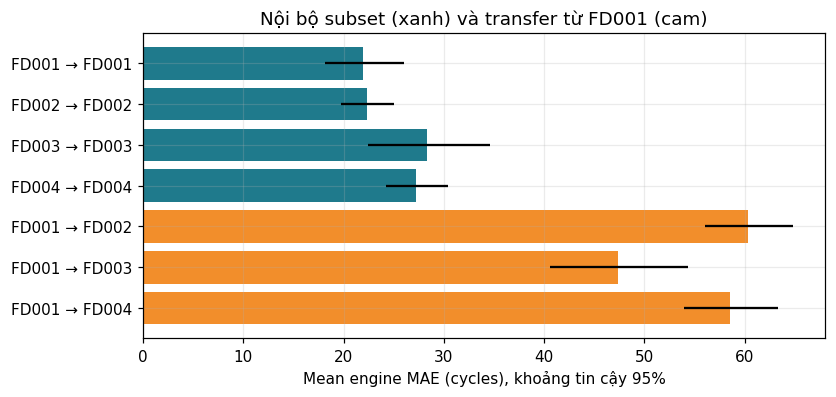

,mean_engine_mae,within_mae,ratio
target,,,
FD002,60.3215,22.3556,2.6983
FD003,47.3949,28.3255,1.6732
FD004,58.5731,27.2218,2.1517


In [3]:
within = cross.loc[cross["type"].eq("within_subset")].set_index("target")["mean_engine_mae"]
transfer = cross.loc[cross["type"].eq("transfer")].set_index("target")
transfer = transfer.assign(within_mae=within.loc[transfer.index], ratio=lambda frame: frame["mean_engine_mae"] / frame["within_mae"])

fig, ax = plt.subplots(figsize=(8, 3.6))
labels = cross["source"] + " → " + cross["target"]
colors = np.where(cross["type"].eq("transfer"), "#f28e2b", "#1f7a8c")
ax.barh(labels, cross["mean_engine_mae"], color=colors,
        xerr=[cross["mean_engine_mae"] - cross["ci_lower"], cross["ci_upper"] - cross["mean_engine_mae"]])
ax.invert_yaxis()
ax.set(xlabel="Mean engine MAE (cycles), khoảng tin cậy 95%", title="Nội bộ subset (xanh) và transfer từ FD001 (cam)")
plt.show()
transfer[["mean_engine_mae", "within_mae", "ratio"]]

Transfer từ FD001 làm MAE tăng khoảng 1.7 đến 2.7 lần so với evaluation nội bộ trên
cùng target subset, và khoảng tin cậy của transfer không chồng lên khoảng tin cậy của
evaluation nội bộ. FD002 và FD004 có sáu điều kiện vận hành, FD003 và FD004 có hai dạng
lỗi, trong khi FD001 chỉ có một điều kiện và một dạng lỗi. Model fit riêng trên FD001
không nên được dùng trực tiếp cho FD002–FD004 nếu chưa có retraining hoặc domain
adaptation.

## 2. Thử nghiệm cải thiện bằng nested cross-validation

Vòng ngoài giữ riêng từng nhóm engine để đánh giá. Vòng trong chỉ dùng các engine còn
lại để chọn lần lượt window, tham số HGB và trọng số mẫu. Mọi phương án được so trên
cùng các cycle từ 30 trở đi. Bảng `ablation_metrics.csv` và `paired_comparison.csv`
được tính lại từ `outer_predictions.parquet`.

In [4]:
RUN = ROOT / "outputs" / "experiments" / "rul_improvement" / "20260928_rebuild"
outer = pd.read_parquet(RUN / "outer_predictions.parquet")
ablation = pd.read_csv(RUN / "ablation_metrics.csv").set_index("stage")
paired_stored = pd.read_csv(RUN / "paired_comparison.csv")
decision = read_json("outputs/experiments/rul_improvement/20260928_rebuild/decision.json")
run_info = read_json("outputs/experiments/rul_improvement/20260928_rebuild/run_info.json")
resamples, seed = int(paired_stored["resamples"].iloc[0]), int(paired_stored["seed"].iloc[0])

tables = {}
for stage in ("baseline", "windows", "parameters", "weights"):
    frame = outer.loc[outer["stage"].eq(stage)].sort_values(["engine_id", "cycle"])
    tables[stage] = engine_metrics(frame)
    assert np.isclose(tables[stage]["mean_engine_mae"].mean(), ablation.loc[stage, "mean_engine_mae"]), stage
    assert np.isclose(tables[stage]["low_rul_engine_mae"].mean(), ablation.loc[stage, "low_rul_engine_mae"]), stage

paired = pd.concat(
    [paired_comparison(tables["baseline"], tables[stage], resamples, seed).assign(stage=stage) for stage in ("windows", "parameters", "weights")],
    ignore_index=True,
)
pd.testing.assert_frame_equal(
    paired[["stage", "metric", "delta", "ci_lower", "ci_upper"]],
    paired_stored[["stage", "metric", "delta", "ci_lower", "ci_upper"]],
    check_dtype=False,
)
print("Ablation và paired comparison khớp với artifact.")
ablation[["mean_engine_mae", "low_rul_engine_mae", "late_or_missed_count", "early_alarm_burden"]]

Ablation và paired comparison khớp với artifact.


,mean_engine_mae,low_rul_engine_mae,late_or_missed_count,early_alarm_burden
stage,,,,
baseline,20.2143,3.6676,49,0.0129
windows,20.2143,3.6676,49,0.0129
parameters,20.2459,3.6730,53,0.0126
weights,20.2459,3.6730,53,0.0126


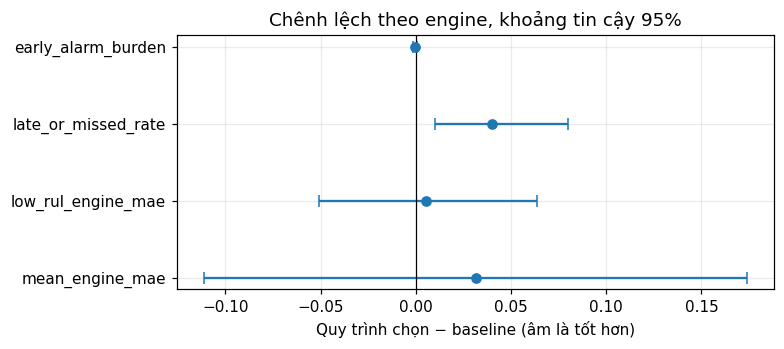

{
  "observed_improvement_meets_plan": false,
  "both_primary_intervals_below_zero": false,
  "default_model": "retain_baseline",
  "interval_scope": "paired engine resampling conditional on stored outer predictions; excludes retraining variability"
}


,baseline,candidate,delta,ci_lower,ci_upper
metric,,,,,
mean_engine_mae,20.2143,20.2459,0.0315,-0.1112,0.1737
low_rul_engine_mae,3.6676,3.6730,0.0054,-0.0506,0.0639
late_or_missed_rate,0.4900,0.5300,0.0400,0.0100,0.0800
early_alarm_burden,0.0129,0.0126,-0.0004,-0.0013,0.0006


In [5]:
final = paired.loc[paired["stage"].eq("weights")].set_index("metric")
fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(final["delta"], final.index, xerr=[final["delta"] - final["ci_lower"], final["ci_upper"] - final["delta"]], fmt="o", capsize=4)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Quy trình chọn − baseline (âm là tốt hơn)", title="Chênh lệch theo engine, khoảng tin cậy 95%")
plt.show()
print(json.dumps(decision, indent=2, ensure_ascii=False))
final[["baseline", "candidate", "delta", "ci_lower", "ci_upper"]]

Quy trình chọn cấu hình giữ nguyên window 30 và cuối cùng không cải thiện metric
chính: MAE toàn bộ và MAE khi RUL ≤ 30 tăng rất nhẹ, khoảng tin cậy chứa 0. Tỷ lệ cảnh
báo trễ hoặc bỏ lỡ tăng từ 0.49 lên 0.53, với khoảng tin cậy nằm hoàn toàn trên 0.
Vì vậy `decision.json` ghi `observed_improvement_meets_plan = false` và model mặc định
vẫn là baseline. Khoảng tin cậy chỉ lấy lại engine trên prediction đã lưu, chưa gồm biến
thiên do huấn luyện lại.

In [6]:
print("Cấu hình cuối:")
print(json.dumps(run_info.get("selected_final", {}), indent=2, ensure_ascii=False))
pd.read_csv(RUN / "test_comparison.csv")[["model", "mean_engine_mae", "rmse", "nasa_score", "low_rul_engine_mae"]]

Cấu hình cuối:
{
  "window": 30,
  "weight_scheme": "uniform",
  "learning_rate": 0.05,
  "max_iter": 200,
  "max_leaf_nodes": 31,
  "min_samples_leaf": 20,
  "l2_regularization": 0.0
}


,model,mean_engine_mae,rmse,nasa_score,low_rul_engine_mae
0,baseline,15.349,20.5413,1513.2577,4.383
1,selected_final,15.349,20.5413,1513.2577,4.383


## Tóm tắt

- Bảy evaluation cross-dataset và toàn bộ bảng của thử nghiệm cải thiện tính lại
  khớp với artifact.
- Transfer từ FD001 sang subset khác làm sai số tăng rõ rệt.
- Nested CV không tìm được cấu hình tốt hơn baseline theo tiêu chí đã chốt trước;
  đây là negative result và được giữ nguyên trong báo cáo.